# Lab 05 - Task 1: Car Price Prediction using Linear Regression

**Course:** AL3002 (Machine Learning Lab) | **Instructor:** Muhammad Khalid

**Goal:** Predict car prices from attributes such as engine size, horsepower, weight, brand, body type, etc.

**Pipeline:** Load data -> EDA -> Data wrangling -> Train/test split -> Linear Regression -> Evaluation metrics -> Plots of training and testing results

## 1. Imports and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

# Change this path if your file is somewhere else
df = pd.read_csv('car_price.csv')
print('Shape:', df.shape)
df.head()

Shape: (210, 25)


,CarName,carbody,drivewheel,enginelocation,fueltype,aspiration,doornumber,cylindernumber,enginetype,fuelsystem,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,alfa-romero giulia,convertible,rwd,front,gas,std,two,four,dohc,mpfi,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495.0
1,alfa-romero stelvio,convertible,rwd,front,gas,std,two,four,dohc,mpfi,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500.0
2,alfa-romero Quadrifoglio,hatchback,rwd,front,gas,std,two,six,ohcv,mpfi,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,16500.0
3,audi 100 ls,sedan,fwd,front,gas,std,four,four,ohc,mpfi,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,13950.0
4,audi 100ls,sedan,4wd,front,gas,std,four,five,ohc,mpfi,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,17450.0


## 2. Exploratory Data Analysis (EDA)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CarName           210 non-null    str    
 1   carbody           210 non-null    str    
 2   drivewheel        210 non-null    str    
 3   enginelocation    210 non-null    str    
 4   fueltype          210 non-null    str    
 5   aspiration        210 non-null    str    
 6   doornumber        210 non-null    str    
 7   cylindernumber    210 non-null    str    
 8   enginetype        210 non-null    str    
 9   fuelsystem        210 non-null    str    
 10  symboling         210 non-null    int64  
 11  wheelbase         210 non-null    float64
 12  carlength         210 non-null    float64
 13  carwidth          210 non-null    float64
 14  carheight         210 non-null    float64
 15  curbweight        210 non-null    int64  
 16  enginesize        210 non-null    int64  
 17  borerati

In [3]:
# Missing values and duplicate rows
print('Missing values per column:')
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() else 'None - no missing values')
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
None - no missing values

Duplicate rows: 5


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
symboling,210.0,0.828571,1.244757,-2.00,0.000,1.00,2.0000,3.00
wheelbase,210.0,98.947143,6.172319,86.60,94.500,97.00,102.4000,120.90
carlength,210.0,174.354286,12.457557,141.10,166.800,173.20,183.5000,208.10
carwidth,210.0,65.935714,2.141794,60.30,64.125,65.50,66.9000,72.30
carheight,210.0,53.768571,2.489242,47.80,52.000,54.10,55.5750,59.80
curbweight,210.0,2565.909524,522.279331,1488.00,2174.250,2422.50,2953.5000,4066.00
enginesize,210.0,127.266667,41.297095,61.00,98.000,120.00,145.7500,326.00
boreratio,210.0,3.333905,0.270150,2.54,3.150,3.32,3.5875,3.94
stroke,210.0,3.258286,0.311277,2.07,3.110,3.29,3.4100,4.17
compressionratio,210.0,10.224381,4.068746,7.00,8.525,9.00,9.4000,23.00


In [5]:
# Categorical columns and their categories
cat_cols = df.select_dtypes(include='object').columns.drop('CarName')
for c in cat_cols:
    print(c, '->', df[c].value_counts().to_dict())

carbody -> {'sedan': 98, 'hatchback': 71, 'wagon': 27, 'hardtop': 8, 'convertible': 6}
drivewheel -> {'fwd': 121, 'rwd': 80, '4wd': 9}
enginelocation -> {'front': 207, 'rear': 3}
fueltype -> {'gas': 188, 'diesel': 22}
aspiration -> {'std': 171, 'turbo': 39}
doornumber -> {'four': 119, 'two': 91}
cylindernumber -> {'four': 163, 'six': 25, 'five': 11, 'eight': 5, 'two': 4, 'three': 1, 'twelve': 1}
enginetype -> {'ohc': 150, 'l': 15, 'ohcf': 15, 'ohcv': 13, 'dohc': 12, 'rotor': 4, 'dohcv': 1}
fuelsystem -> {'mpfi': 96, '2bbl': 67, 'idi': 22, '1bbl': 11, 'spdi': 9, '4bbl': 3, 'mfi': 1, 'spfi': 1}


/tmp/ipykernel_337/3273206580.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.drop('CarName')


**Observation:** there are no missing values, but there are a few duplicate rows. `CarName` mixes brand and model and has spelling mistakes (e.g. `maxda`, `porcshce`, `toyouta`, `vokswagen`, `vw`), so it needs cleaning.

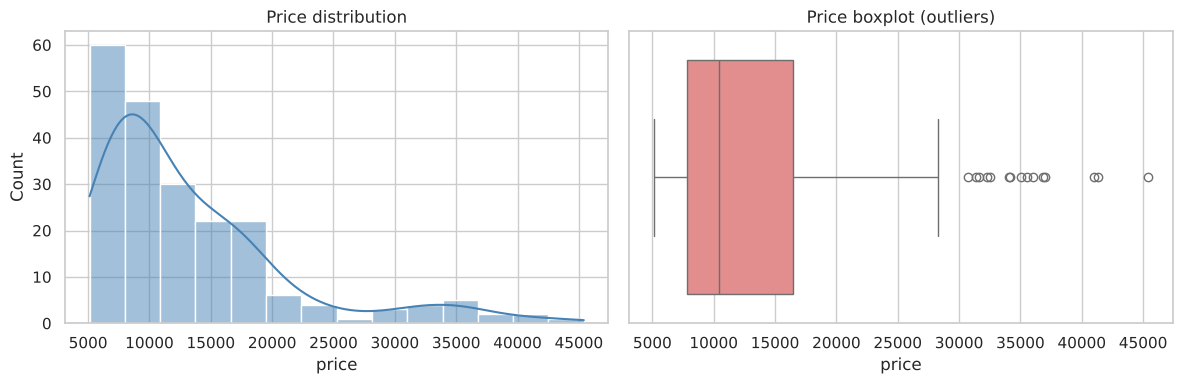

In [6]:
# Price distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], kde=True, ax=ax[0], color='steelblue')
ax[0].set_title('Price distribution')
sns.boxplot(x=df['price'], ax=ax[1], color='lightcoral')
ax[1].set_title('Price boxplot (outliers)')
plt.tight_layout(); plt.show()

Price is right-skewed: most cars are cheap, and a few luxury brands pull the tail to the right.

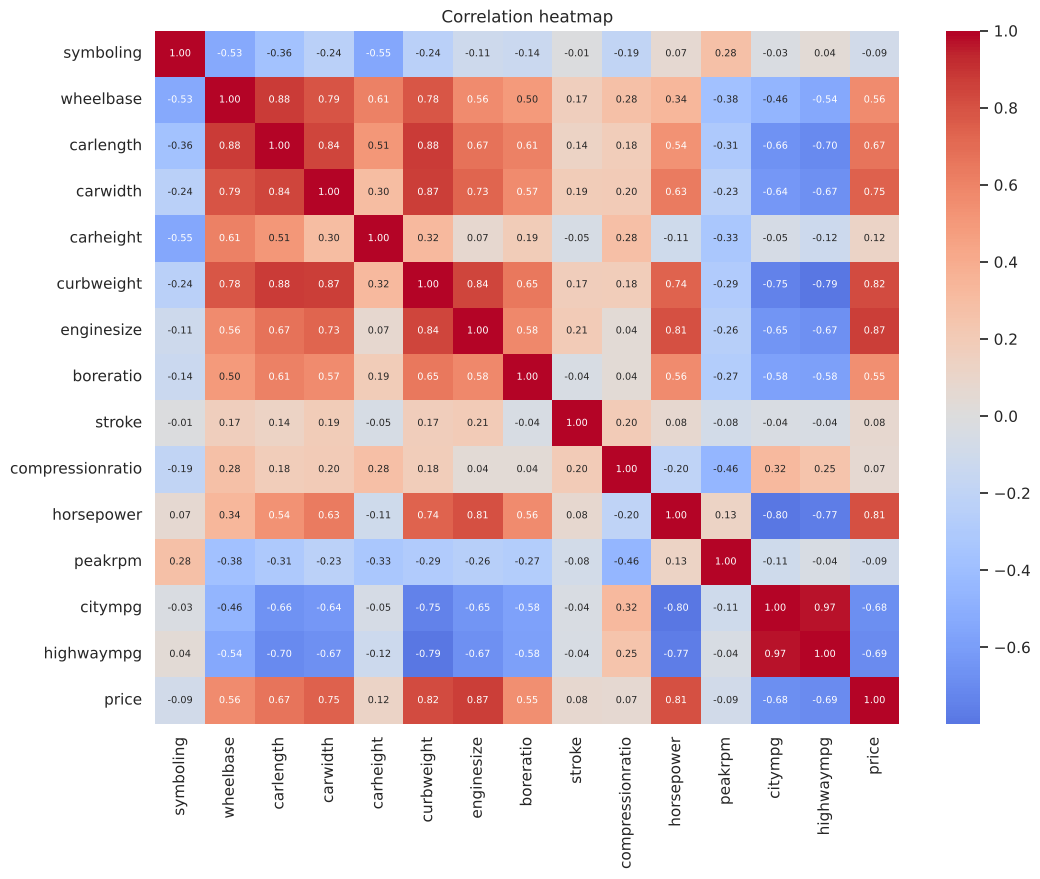

price               1.000
enginesize          0.873
curbweight          0.823
horsepower          0.808
carwidth            0.747
carlength           0.667
wheelbase           0.558
boreratio           0.546
carheight           0.121
stroke              0.076
compressionratio    0.066
symboling          -0.087
peakrpm            -0.091
citympg            -0.684
highwaympg         -0.694
Name: price, dtype: float64


In [7]:
# Correlation of numeric features with price
num = df.select_dtypes(include=np.number)
plt.figure(figsize=(12, 9))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation heatmap')
plt.show()

print(num.corr()['price'].sort_values(ascending=False).round(3))

**Observation:** `enginesize`, `curbweight`, `horsepower`, `carwidth` and `cylindernumber` have the strongest positive correlation with price. `citympg` and `highwaympg` are strongly negative (bigger, more powerful cars use more fuel and cost more). Several predictors are also highly correlated with each other (multicollinearity), e.g. `curbweight`, `enginesize`, `horsepower`.

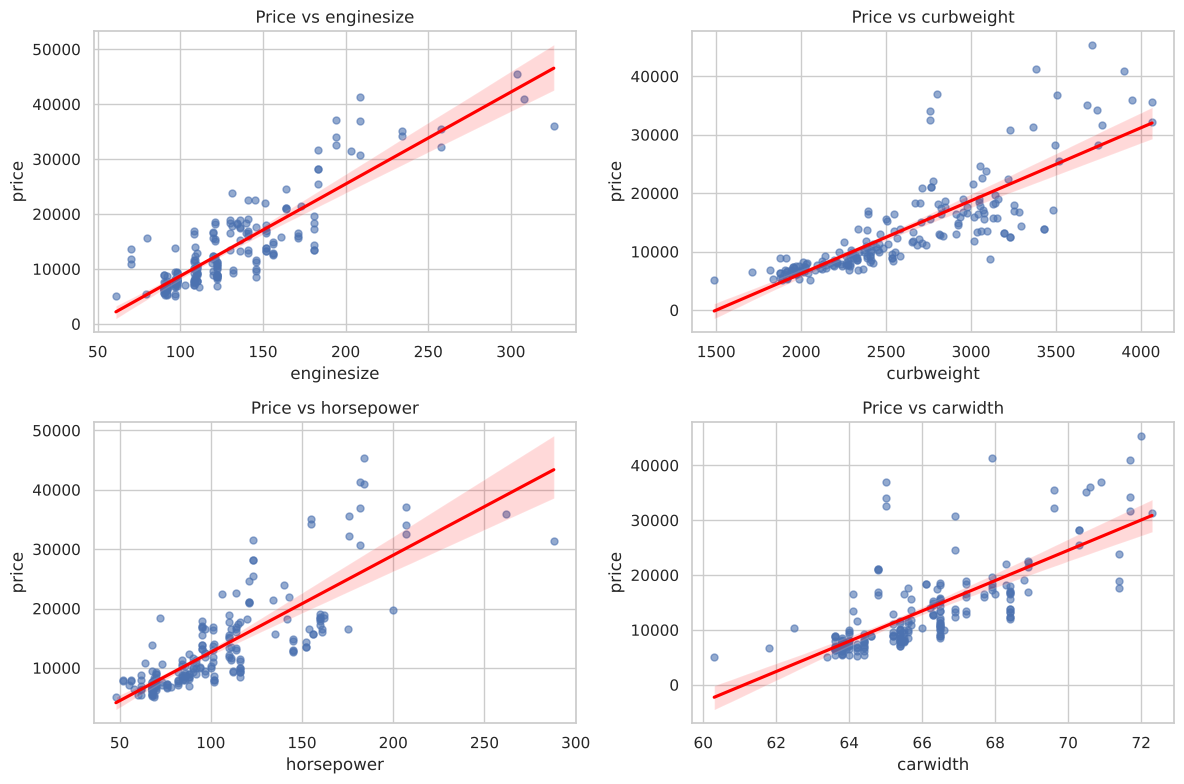

In [8]:
# Price vs key numeric features
feats = ['enginesize', 'curbweight', 'horsepower', 'carwidth']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, f in zip(axes.ravel(), feats):
    sns.regplot(x=f, y='price', data=df, ax=ax, scatter_kws={'alpha': 0.6, 's': 25}, line_kws={'color': 'red'})
    ax.set_title(f'Price vs {f}')
plt.tight_layout(); plt.show()

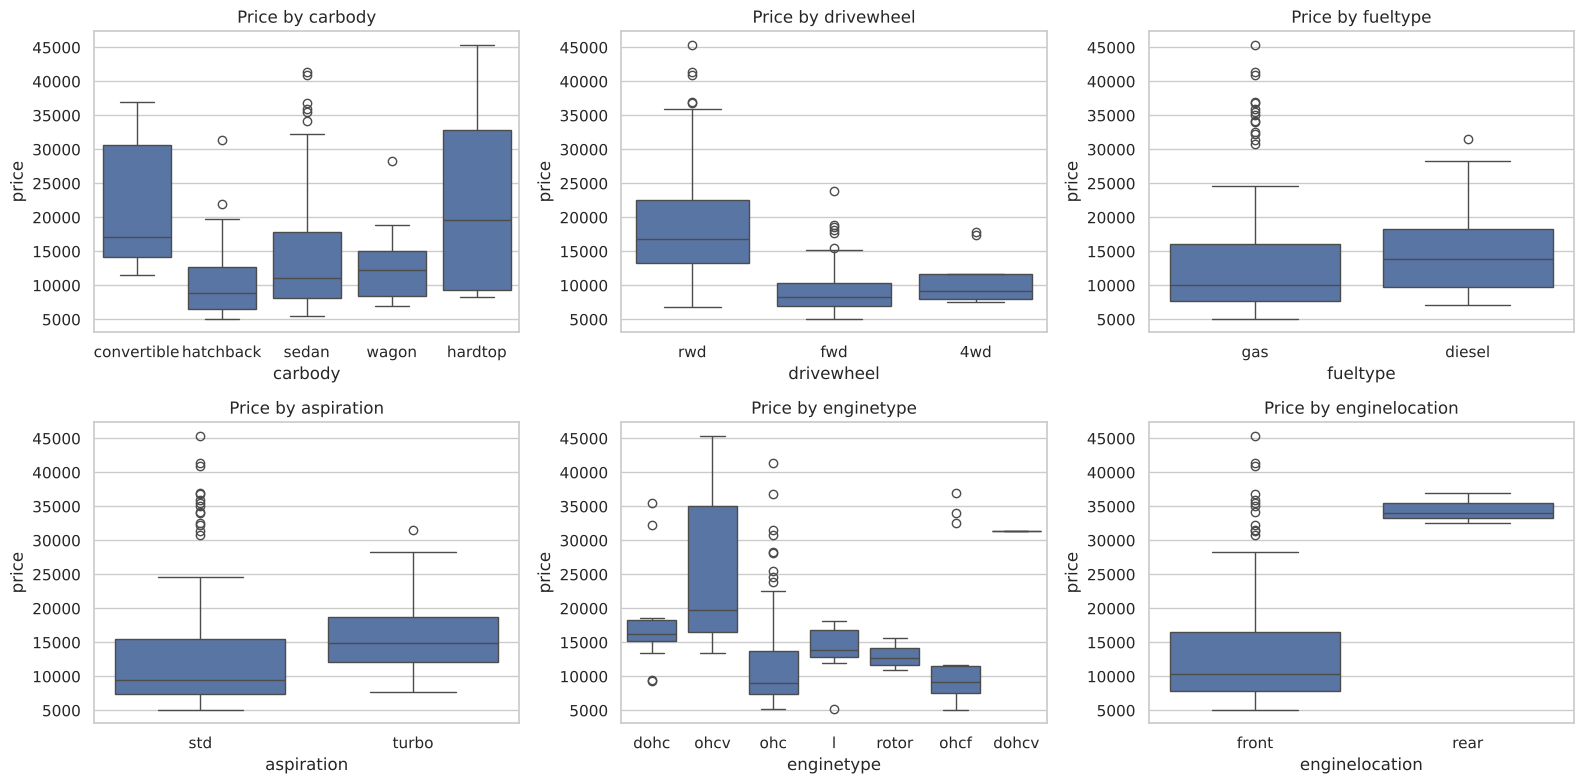

In [9]:
# Price vs categorical features
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ['carbody', 'drivewheel', 'fueltype', 'aspiration', 'enginetype', 'enginelocation']):
    sns.boxplot(x=c, y='price', data=df, ax=ax)
    ax.set_title(f'Price by {c}')
plt.tight_layout(); plt.show()

## 3. Data Wrangling

### 3.1 Remove duplicates

In [10]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Removed {before - len(df)} duplicate rows. New shape: {df.shape}')

Removed 5 duplicate rows. New shape: (205, 25)


### 3.2 Extract brand from `CarName` and fix spelling mistakes

In [11]:
df['brand'] = df['CarName'].str.split().str[0].str.lower()

typo_fix = {'maxda': 'mazda', 'porcshce': 'porsche', 'toyouta': 'toyota',
            'vokswagen': 'volkswagen', 'vw': 'volkswagen'}
df['brand'] = df['brand'].replace(typo_fix)

print('Unique brands:', df['brand'].nunique())
print(df['brand'].value_counts().to_dict())

# Model names are mostly unique, so we drop CarName and keep brand only
df = df.drop(columns='CarName')

Unique brands: 22
{'toyota': 32, 'nissan': 18, 'mazda': 17, 'honda': 13, 'mitsubishi': 13, 'subaru': 12, 'volkswagen': 12, 'peugeot': 11, 'volvo': 11, 'dodge': 9, 'bmw': 8, 'buick': 8, 'audi': 7, 'plymouth': 7, 'saab': 6, 'porsche': 5, 'isuzu': 4, 'alfa-romero': 3, 'chevrolet': 3, 'jaguar': 3, 'renault': 2, 'mercury': 1}


### 3.3 Convert number words to numbers

In [12]:
cyl_map = {'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'eight': 8, 'twelve': 12}
df['cylindernumber'] = df['cylindernumber'].map(cyl_map)
df['doornumber'] = df['doornumber'].map({'two': 2, 'four': 4})
df[['cylindernumber', 'doornumber']].describe().T

,count,mean,std,min,25%,50%,75%,max
cylindernumber,205.0,4.380488,1.080854,2.0,4.0,4.0,4.0,12.0
doornumber,205.0,3.121951,0.994966,2.0,2.0,4.0,4.0,4.0


### 3.4 Outliers

In this dataset the high prices belong to genuine luxury cars (BMW, Jaguar, Buick, Porsche), not data errors, so they are **kept**. Removing them would make the model blind to the luxury segment.

In [13]:
Q1, Q3 = df['price'].quantile([0.25, 0.75])
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print(f'IQR upper fence: {upper:.0f}')
print('Rows above fence:', (df['price'] > upper).sum())
df[df['price'] > upper][['brand', 'carbody', 'enginesize', 'horsepower', 'price']].sort_values('price', ascending=False)

IQR upper fence: 29576
Rows above fence: 15


,brand,carbody,enginesize,horsepower,price
74,buick,hardtop,304,184,45400.0
16,bmw,sedan,209,182,41315.0
73,buick,sedan,308,184,40960.0
128,porsche,convertible,194,207,37028.0
17,bmw,sedan,209,182,36880.0
49,jaguar,sedan,326,262,36000.0
48,jaguar,sedan,258,176,35550.0
72,buick,convertible,234,155,35056.0
71,buick,sedan,234,155,34184.0
127,porsche,hardtop,194,207,34028.0


### 3.5 One-hot encode categorical columns

In [14]:
X = pd.get_dummies(df.drop(columns='price'), drop_first=True, dtype=int)
y = df['price']
print('Feature matrix shape:', X.shape)
X.head()

Feature matrix shape: (205, 59)


,doornumber,cylindernumber,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,carbody_hardtop,carbody_hatchback,carbody_sedan,carbody_wagon,drivewheel_fwd,drivewheel_rwd,enginelocation_rear,fueltype_gas,aspiration_turbo,...,fuelsystem_mfi,fuelsystem_mpfi,fuelsystem_spdi,fuelsystem_spfi,brand_audi,brand_bmw,brand_buick,brand_chevrolet,brand_dodge,brand_honda,brand_isuzu,brand_jaguar,brand_mazda,brand_mercury,brand_mitsubishi,brand_nissan,brand_peugeot,brand_plymouth,brand_porsche,brand_renault,brand_saab,brand_subaru,brand_toyota,brand_volkswagen,brand_volvo
0,2,4,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,0,0,0,0,0,1,0,1,0,...,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,4,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,0,0,0,0,0,1,0,1,0,...,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2,6,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,0,1,0,0,0,1,0,1,0,...,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,4,4,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,0,0,1,0,1,0,0,1,0,...,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,4,5,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,0,0,1,0,0,0,0,1,0,...,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 4. Train / Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (164, 59) | Test: (41, 59)


## 5. Implement Linear Regression

In [16]:
LR = LinearRegression()
ModelLR = LR.fit(X_train, y_train)

PredictionLR = ModelLR.predict(X_test)         # test predictions
PredictionTrain = ModelLR.predict(X_train)     # train predictions

print('Intercept:', round(ModelLR.intercept_, 2))
print('Number of coefficients:', len(ModelLR.coef_))

Intercept: -27433.05
Number of coefficients: 59


In [17]:
# Sample of actual vs predicted (test set)
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': PredictionLR.round(0)})
comparison['Error'] = comparison['Predicted'] - comparison['Actual']
comparison.head(10)

,Actual,Predicted,Error
0,30760.000,29722.0,-1038.000
1,17859.167,21334.0,3474.833
2,9549.000,10420.0,871.000
3,11850.000,12830.0,980.000
4,28248.000,32447.0,4199.000
5,7799.000,6307.0,-1492.000
6,7788.000,7557.0,-231.000
7,9258.000,7280.0,-1978.000
8,10198.000,8979.0,-1219.000
9,7775.000,7620.0,-155.000


## 6. Evaluate Linear Regression using Different Metrics

In [18]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        'R2 Score': r2_score(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'MAPE (%)': np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
    }

results = pd.DataFrame({
    'Train': evaluate(y_train, PredictionTrain),
    'Test': evaluate(y_test, PredictionLR),
}).round(3)
results

,Train,Test
R2 Score,0.973,0.895
MAE,958.752,1942.068
MSE,1627419.802,8283565.717
RMSE,1275.704,2878.118
MAPE (%),8.116,15.573


In [19]:
print('=================== LR Testing Accuracy ===================')
print('Testing Accuracy (R2 x 100): %.2f %%' % (r2_score(y_test, PredictionLR) * 100))
print('Training Accuracy (R2 x 100): %.2f %%' % (r2_score(y_train, PredictionTrain) * 100))

=================== LR Testing Accuracy ===================
Testing Accuracy (R2 x 100): 89.51 %
Training Accuracy (R2 x 100): 97.27 %


**Metric guide**
- **R2:** share of price variance explained by the model (1.0 is perfect).
- **MAE:** average absolute error in price units.
- **MSE / RMSE:** squared error penalises large mistakes more; RMSE is back in price units.
- **MAPE:** average percentage error.

## 7. Plot Training and Testing Results

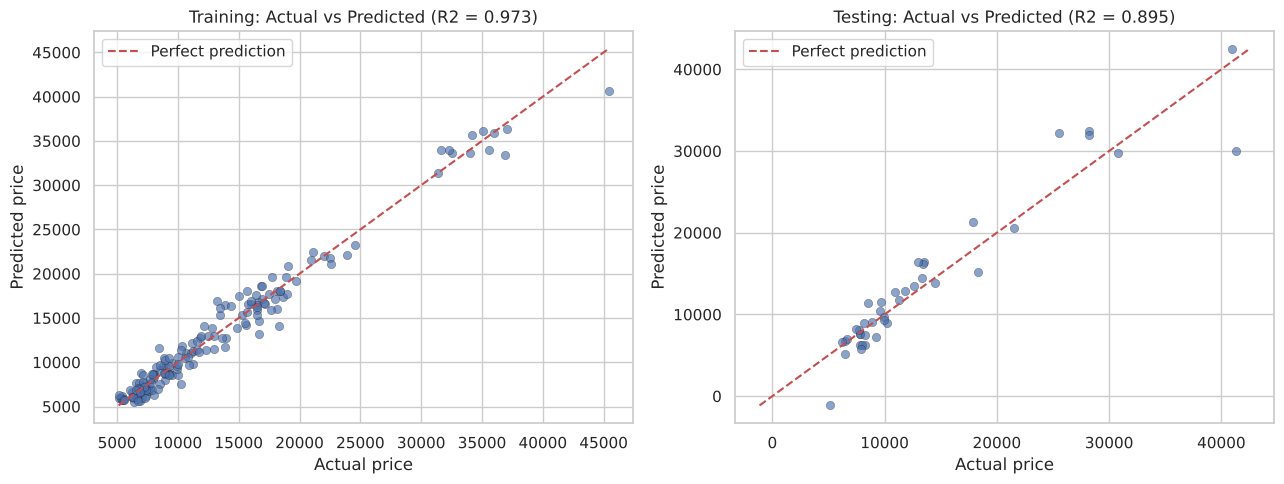

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (a, p, name) in zip(axes, [(y_train, PredictionTrain, 'Training'), (y_test, PredictionLR, 'Testing')]):
    ax.scatter(a, p, alpha=0.65, edgecolor='k', linewidth=0.3)
    lims = [min(a.min(), p.min()), max(a.max(), p.max())]
    ax.plot(lims, lims, 'r--', label='Perfect prediction')
    ax.set_xlabel('Actual price'); ax.set_ylabel('Predicted price')
    ax.set_title(f'{name}: Actual vs Predicted (R2 = {r2_score(a, p):.3f})')
    ax.legend()
plt.tight_layout(); plt.show()

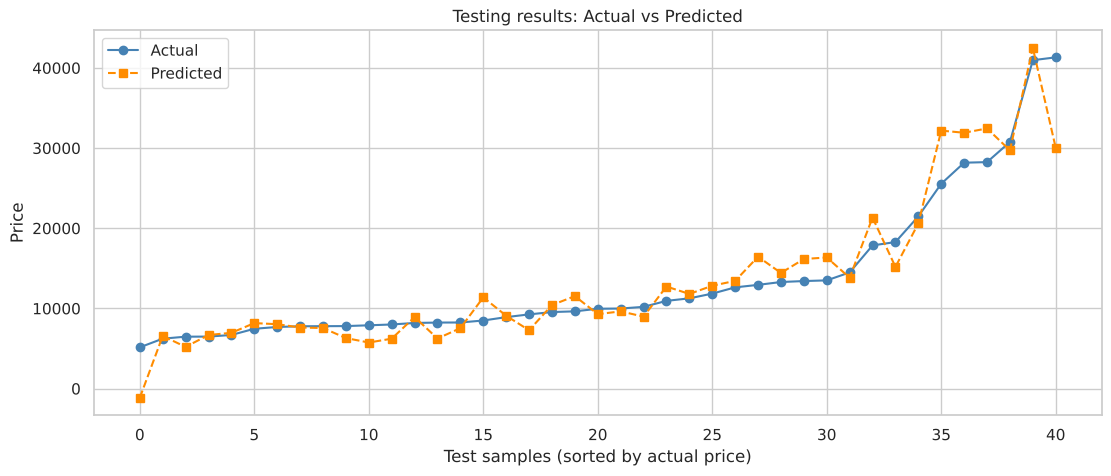

In [21]:
# Test set: actual vs predicted, sample by sample
order = np.argsort(y_test.values)
plt.figure(figsize=(13, 5))
plt.plot(y_test.values[order], 'o-', label='Actual', color='steelblue')
plt.plot(PredictionLR[order], 's--', label='Predicted', color='darkorange')
plt.xlabel('Test samples (sorted by actual price)'); plt.ylabel('Price')
plt.title('Testing results: Actual vs Predicted')
plt.legend(); plt.show()

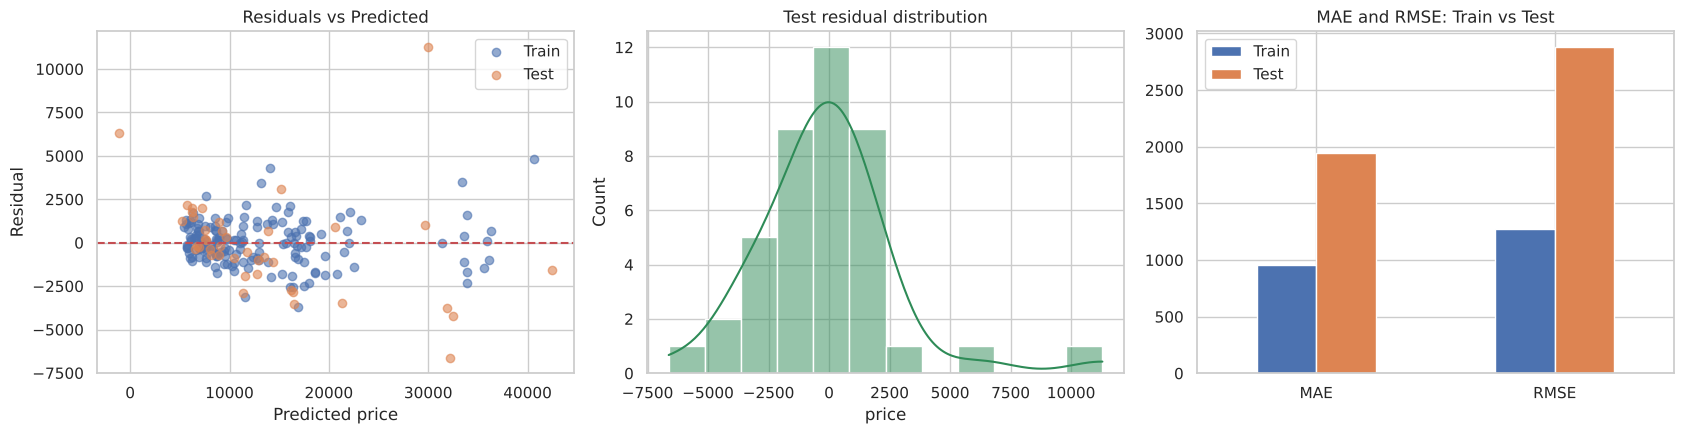

In [22]:
# Residual analysis
res_train = y_train - PredictionTrain
res_test = y_test - PredictionLR

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(PredictionTrain, res_train, alpha=0.6, label='Train')
axes[0].scatter(PredictionLR, res_test, alpha=0.6, label='Test')
axes[0].axhline(0, color='r', ls='--')
axes[0].set_xlabel('Predicted price'); axes[0].set_ylabel('Residual'); axes[0].set_title('Residuals vs Predicted'); axes[0].legend()

sns.histplot(res_test, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title('Test residual distribution')

metrics_plot = results.loc[['MAE', 'RMSE']]
metrics_plot.plot(kind='bar', ax=axes[2], rot=0)
axes[2].set_title('MAE and RMSE: Train vs Test')
plt.tight_layout(); plt.show()

## 8. Linear Regression Coefficients

Intercept: -27433.05

Top 15 coefficients by magnitude:
enginelocation_rear    6776.57
enginetype_rotor       6433.19
brand_buick            6107.55
brand_bmw              5783.39
brand_porsche          5012.08
brand_subaru          -4447.88
brand_plymouth        -4312.19
brand_mitsubishi      -4297.07
brand_dodge           -4254.52
brand_chevrolet       -3863.30
carbody_wagon         -3698.40
carbody_hatchback     -3498.91
boreratio             -3388.49
carbody_sedan         -3264.22
fuelsystem_2bbl        2977.97
dtype: float64


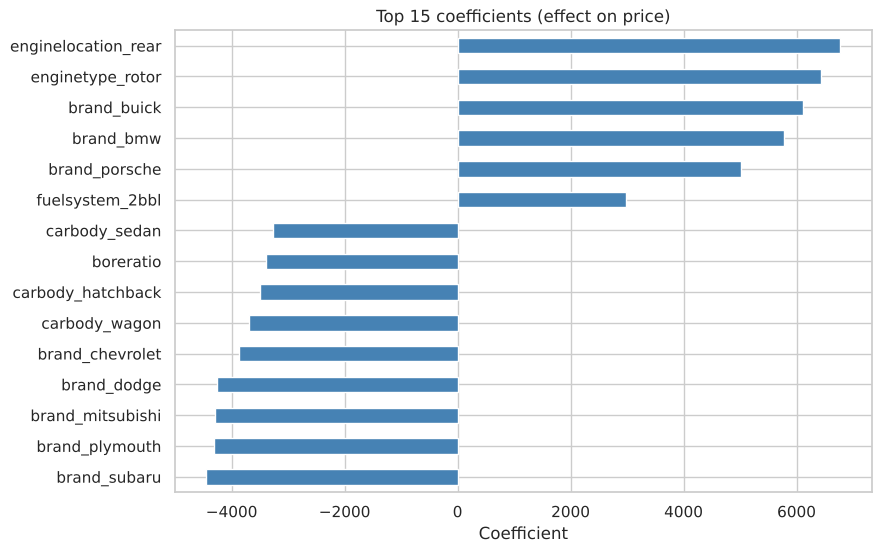

In [23]:
coef = pd.Series(ModelLR.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print('Intercept:', round(ModelLR.intercept_, 2))
print('\nTop 15 coefficients by magnitude:')
print(coef.head(15).round(2))

plt.figure(figsize=(9, 6))
coef.head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 15 coefficients (effect on price)'); plt.xlabel('Coefficient'); plt.show()

## 9. Conclusion

**Results (test set, 41 cars, random_state=42):** R2 = 0.895, MAE = about 1,942, RMSE = about 2,878, MAPE = about 15.6%. On the training set, R2 = 0.973, MAE = about 959, RMSE = about 1,276.

**Interpretation**
- The model explains about 90% of the price variation on unseen cars, so Linear Regression is a strong baseline for this dataset.
- Training scores are clearly better than test scores. With 59 features and only 164 training rows, the model is somewhat overfitted (the lab manual warns about this for multiple linear regression).
- Prices are driven mainly by engine size, curb weight, horsepower, cylinders and brand. Luxury brands (Buick, BMW, Porsche) carry a positive premium, while budget brands (Subaru, Plymouth, Dodge, Mitsubishi) and wagon/hatchback bodies carry a negative one.
- The largest errors are on the most expensive cars, where few training examples exist. One cheap car even got a negative predicted price, which is a known weakness of plain Linear Regression.

**Possible improvements:** apply Ridge/Lasso regularisation, predict log(price), use cross-validation, and drop highly correlated features (curbweight, enginesize, horsepower, citympg, highwaympg) to reduce multicollinearity.